In [122]:
import numpy as np

In [123]:
X = np.array([
    [-2, -2],
    [-1.5, -2],
    [-2, -1.5],

    [2, 2],
    [1.5, 2],
    [2, 1.5],

    [-2, 2],
    [-1.5, 2],
    [-2, 1.5]
])

y = np.array([
    0, 0, 0,
    1, 1, 1,
    2, 2, 2
])
print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (9, 2)
y shape: (9,)


In [124]:
y = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
H = np.eye(3)[y]
print(H)

[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]]


In [125]:

W1 = np.array([
    [0.05,-0.08,0.03],
    [-0.04, 0.06, 0.09]
])
W2 = np.array([
    [0.07,-0.02,0.04],
    [-0.06,0.08,-0.03],
    [0.02,0.05,-0.07]
])
b1 = np.zeros(3)
b2 = np.zeros(3)
Z1 = X@W1+b1
def sigmoid(x):
    return 1/(1+np.exp(-x))
A1 = sigmoid(Z1)
Z2 = A1@W2+b2
print(A1)
print(Z2)


[[0.49500017 0.50999867 0.44028635]
 [0.50125    0.5        0.44398611]
 [0.49000133 0.51749286 0.45140389]
 [0.50499983 0.49000133 0.55971365]
 [0.49875    0.5        0.55601389]
 [0.50999867 0.48250714 0.54859611]
 [0.45512111 0.56954622 0.52996405]
 [0.46132739 0.55971365 0.53369884]
 [0.46008512 0.5621765  0.51874122]]
[[ 0.01285582  0.05291421 -0.02632   ]
 [ 0.01396722  0.05217431 -0.02602903]
 [ 0.0122786   0.0541696  -0.027523  ]
 [ 0.01714418  0.05708579 -0.03368   ]
 [ 0.01603278  0.05782569 -0.03397097]
 [ 0.0177214   0.0558304  -0.032477  ]
 [ 0.00828499  0.06295948 -0.03597903]
 [ 0.00938408  0.06223549 -0.03569723]
 [ 0.00885019  0.06170948 -0.03477378]]


In [126]:
def softmax(ap):
    b = ap - np.max(ap, axis = 1, keepdims = True)
    ex = np.exp(b)
    return ex / np.sum(ex, axis = 1, keepdims = True)
A2 = softmax(Z2)
print(A2)


[[0.33306098 0.3466737  0.32026532]
 [0.33336229 0.34634554 0.32029217]
 [0.33291598 0.34715839 0.31992562]
 [0.33431446 0.34793778 0.31774776]
 [0.334012   0.34826714 0.31772085]
 [0.334461   0.34745296 0.31808603]
 [0.33190635 0.35055841 0.31753525]
 [0.33220464 0.35023438 0.31756098]
 [0.33204994 0.35007404 0.31787602]]


In [127]:
def cross_entropy(a,ap):
    ep = 1e-15
    ap = np.clip(ap,ep,1-ep)
    return -np.sum(a * np.log(ap))
print("loss:", cross_entropy(H,A2))

loss: 9.90580899346226


In [128]:

def backprop():
    global W1, b1, W2, b2
    lr = 0.01
    for i in range(1000):
    
        
        Z1 = X @ W1 + b1
        A1 = sigmoid(Z1)
    
        Z2 = A1 @ W2 + b2
        A2 = softmax(Z2)
    
        
        loss = cross_entropy(H, A2)
    
        if i % 10 == 0:
            print(i, loss)
    
        
        dZ2 = A2 - H
        dW2 = A1.T @ dZ2
        db2 = np.sum(dZ2, axis=0)
    
        dA1 = dZ2 @ W2.T
        dZ1 = dA1 * A1 * (1-A1)
    
        dW1 = X.T @ dZ1
        db1 = np.sum(dZ1, axis=0)
    
        
        W1 -= lr * dW1
        b1 -= lr * db1
        W2 -= lr * dW2
        b2 -= lr * db2
   
backprop()


    

0 9.90580899346226
10 9.880144867925505
20 9.854932162210693
30 9.822052166095773
40 9.773161737860253
50 9.697406977883874
60 9.580381517551565
70 9.404930751551314
80 9.155236066107665
90 8.824444553312173
100 8.421934151594696
110 7.97309394773202
120 7.509559396945377
130 7.0573751115313526
140 6.6313120297295
150 6.236018988229812
160 5.870018998679936
170 5.5293839544418955
180 5.210067624613872
190 4.909012016434845
200 4.624411920293424
210 4.355497087139768
220 4.102119978810535
230 3.8643530244553386
240 3.642203336297769
250 3.4354675848790728
260 3.243698020984044
270 3.066234677120655
280 2.9022651968265607
290 2.7508876237355273
300 2.611163980241448
310 2.4821607193195474
320 2.3629764968222595
330 2.2527594863519687
340 2.150716822818361
350 2.056118492226376
360 1.9682975128666218
370 1.8866477787679115
380 1.8106205368152652
390 1.73972016066547
400 1.6734996588168025
410 1.6115561945847499
420 1.5535267858959985
430 1.4990842789488348
440 1.4479336412444894
450 1.399

In [129]:

Z1 = X @ W1 + b1
A1 = sigmoid(Z1)

Z2 = A1 @ W2 + b2
A2 = softmax(Z2)

In [130]:
predictions = np.argmax(A2, axis=1)

print(predictions)
print(y)
print(A2)

[0 0 0 1 1 1 2 2 2]
[0 0 0 1 1 1 2 2 2]
[[0.97021641 0.00274183 0.02704176]
 [0.96995785 0.00295678 0.02708537]
 [0.96457432 0.00316673 0.03225895]
 [0.00194801 0.95680497 0.04124702]
 [0.00216767 0.95131352 0.04651881]
 [0.00220906 0.95745398 0.04033696]
 [0.01865633 0.04970975 0.93163392]
 [0.01619264 0.0585527  0.92525466]
 [0.03269646 0.04319494 0.92410861]]


In [131]:
X_new = np.array([
    [-1.7, -1.8],   
    [-2.3, -2.1],   

    [1.8, 1.7],     
    [2.3, 2.1],     

    [-1.8, 1.7],    
    [-2.2, 2.3]    
])
Z1_new = X_new @ W1 + b1
A1_new = sigmoid(Z1_new)

Z2_new = A1_new @ W2 + b2
A2_new = softmax(Z2_new)

prediction = np.argmax(A2_new, axis=1)

print(A2_new)
print(prediction)


[[0.96837622 0.00298615 0.02863762]
 [0.97092084 0.00264124 0.02643792]
 [0.00214842 0.95553421 0.04231738]
 [0.00186769 0.95796728 0.04016504]
 [0.02317434 0.04886353 0.92796214]
 [0.01584624 0.05085087 0.93330289]]
[0 0 1 1 2 2]


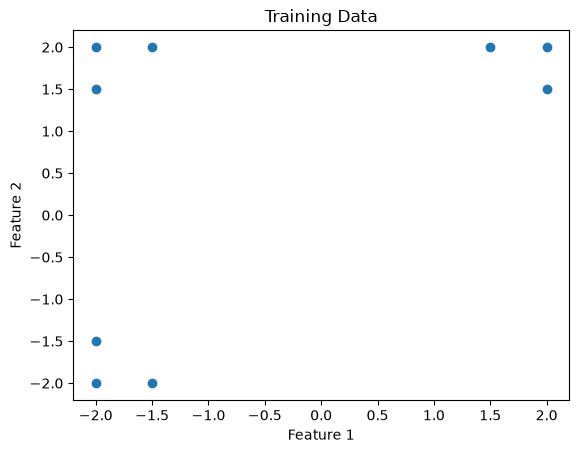

In [132]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1])

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Training Data")

plt.show()

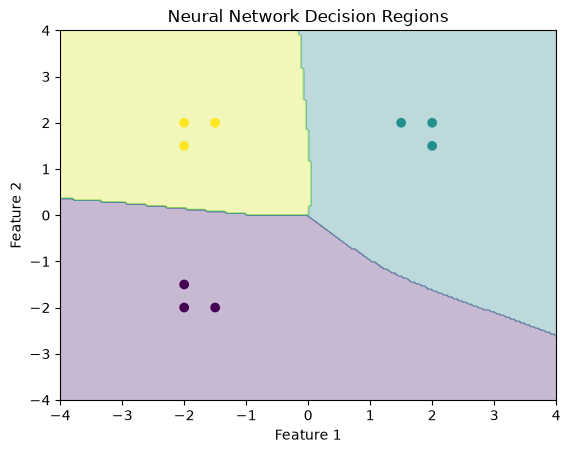

In [133]:
import numpy as np
import matplotlib.pyplot as plt

# Create lots of points covering the whole area
x1 = np.linspace(-4, 4, 200)
x2 = np.linspace(-4, 4, 200)

xx, yy = np.meshgrid(x1, x2)

grid = np.c_[xx.ravel(), yy.ravel()]

# Run the grid through your trained network
Z1_grid = grid @ W1 + b1
A1_grid = sigmoid(Z1_grid)

Z2_grid = A1_grid @ W2 + b2
A2_grid = softmax(Z2_grid)

pred_grid = np.argmax(A2_grid, axis=1)

# Put predictions back into a 2D grid
pred_grid = pred_grid.reshape(xx.shape)

# Plot decision regions
plt.contourf(xx, yy, pred_grid, alpha=0.3)

# Plot original training points
plt.scatter(X[:, 0], X[:, 1], c=y)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Neural Network Decision Regions")

plt.show()

In [134]:
X_test = np.array([
    [0, 0],
    [-0.5, -0.5],
    [0.5, 0.5],
    [-0.5, 0.5],
    [0.5, -0.5],

    [-1, 0],
    [0, -1],
    [1, 0],
    [0, 1],

    [-1, 1],
    [1, 1],
    [-1, -1],
    [1, -1]
])
Z1_new = X_test @ W1 + b1
A1_new = sigmoid(Z1_new)

Z2_new = A1_new @ W2 + b2
A2_new = softmax(Z2_new)

prediction = np.argmax(A2_new, axis=1)

print(A2_new)
print(prediction)

[[0.32812535 0.33107926 0.34079539]
 [0.8148979  0.03609202 0.14901008]
 [0.03151853 0.81094151 0.15753995]
 [0.12090153 0.13579962 0.74329885]
 [0.45885132 0.47006108 0.0710876 ]
 [0.49731905 0.0412918  0.46138915]
 [0.90693795 0.04860933 0.04445272]
 [0.04774568 0.90507379 0.04718053]
 [0.0291368  0.46094354 0.50991966]
 [0.04618837 0.06824763 0.885564  ]
 [0.00534929 0.92877463 0.06587609]
 [0.93862797 0.00706006 0.05431197]
 [0.50704096 0.47242018 0.02053886]]
[2 0 1 2 1 0 0 1 2 2 1 0 0]


In [135]:
X_test = np.array([
    [-10, -10],
    [10, 10],
    [-10, 10],
    [10, -10],

    [-20, 0],
    [20, 0],
    [0, -20],
    [0, 20]
])
Z1_new = X_test @ W1 + b1
A1_new = sigmoid(Z1_new)

Z2_new = A1_new @ W2 + b2
A2_new = softmax(Z2_new)

prediction = np.argmax(A2_new, axis=1)

print(A2_new)
print(prediction)

[[0.97327855 0.00242264 0.02429882]
 [0.0017182  0.95877402 0.03950779]
 [0.00968257 0.05750067 0.93281676]
 [0.8064865  0.18870645 0.00480705]
 [0.76638305 0.0091698  0.22444715]
 [0.00701109 0.97475362 0.0182353 ]
 [0.97439705 0.00310708 0.02249586]
 [0.00256595 0.92981146 0.06762258]]
[0 1 2 0 0 1 0 1]


In [136]:
X_test = np.random.uniform(-4, 4, size=(100, 2))
Z1_new = X_test @ W1 + b1
A1_new = sigmoid(Z1_new)

Z2_new = A1_new @ W2 + b2
A2_new = softmax(Z2_new)

prediction = np.argmax(A2_new, axis=1)

print(A2_new)
print(prediction)

[[0.36871812 0.62143245 0.00984944]
 [0.00459528 0.85184191 0.14356281]
 [0.93206433 0.02316675 0.04476892]
 [0.00473051 0.84076013 0.15450936]
 [0.96593848 0.01188025 0.02218127]
 [0.00471268 0.9410718  0.05421552]
 [0.01453761 0.622973   0.36248939]
 [0.04432409 0.93513962 0.02053628]
 [0.88746947 0.00669636 0.10583416]
 [0.15904093 0.81063585 0.03032322]
 [0.00370524 0.88653595 0.1097588 ]
 [0.01148954 0.07711172 0.91139873]
 [0.62075014 0.37120913 0.00804073]
 [0.00243512 0.95460091 0.04296397]
 [0.00283963 0.95988567 0.03727469]
 [0.94183301 0.00919265 0.04897435]
 [0.66095062 0.33172224 0.00732714]
 [0.30506517 0.68409905 0.01083577]
 [0.77824055 0.21611663 0.00564282]
 [0.00174555 0.9588713  0.03938315]
 [0.01646346 0.87470534 0.1088312 ]
 [0.0025841  0.93040319 0.06701271]
 [0.01374802 0.05446073 0.93179125]
 [0.01589702 0.04884139 0.93526159]
 [0.5241353  0.46735207 0.00851263]
 [0.00176798 0.95754048 0.04069153]
 [0.95098244 0.00466114 0.04435642]
 [0.74386646 0.25034379 0.00

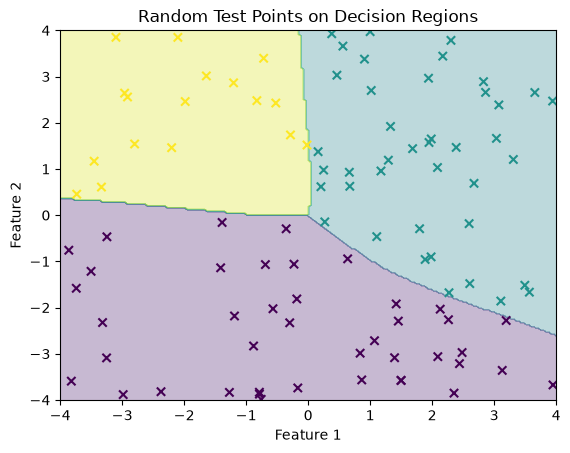

In [137]:
# Forward pass for the 100 random points

Z1_test = X_test @ W1 + b1
A1_test = sigmoid(Z1_test)

Z2_test = A1_test @ W2 + b2
A2_test = softmax(Z2_test)

predictions_test = np.argmax(A2_test, axis=1)

# Plot decision regions
plt.contourf(xx, yy, pred_grid, alpha=0.3)

# Plot the 100 random points
plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=predictions_test,
    marker="x"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Random Test Points on Decision Regions")

plt.show()

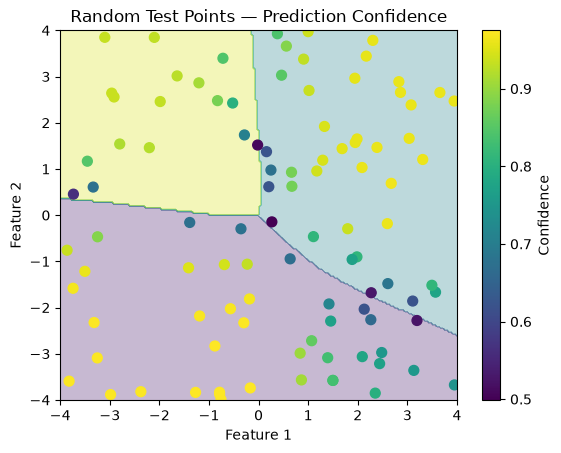

In [138]:
confidence = np.max(A2_test, axis=1)
import matplotlib.pyplot as plt

confidence = np.max(A2_test, axis=1)

plt.contourf(xx, yy, pred_grid, alpha=0.3)

plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=confidence,
    s=50,
    cmap="viridis"
)

plt.colorbar(label="Confidence")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Random Test Points — Prediction Confidence")

plt.show()

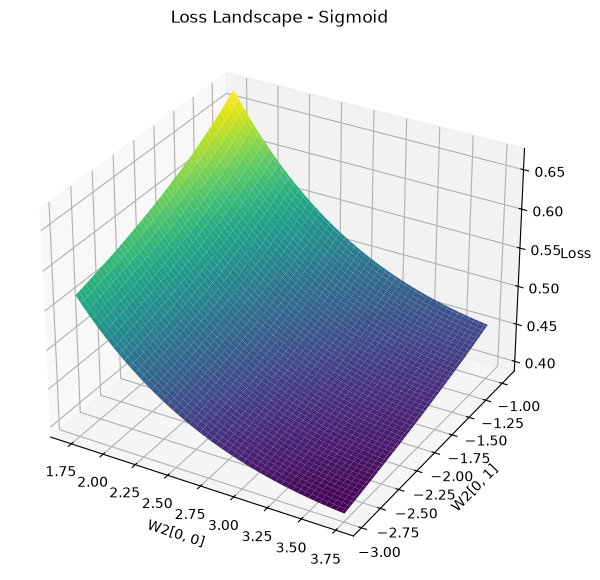

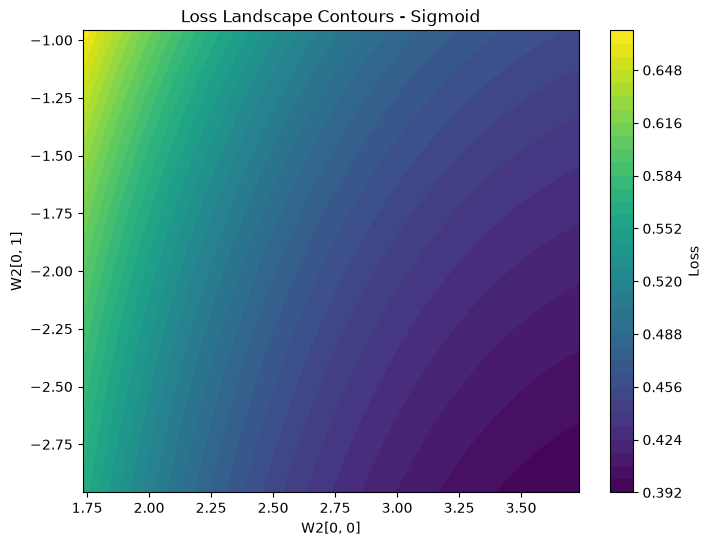

In [139]:

import numpy as np
import matplotlib.pyplot as plt


activation = "sigmoid"  


W2_trained = W2.copy()


w_a = np.linspace(W2_trained[0, 0] - 1,
                  W2_trained[0, 0] + 1, 100)
w_b = np.linspace(W2_trained[0, 1] - 1,
                  W2_trained[0, 1] + 1, 100)

WA, WB = np.meshgrid(w_a, w_b)
loss_grid = np.zeros_like(WA)

def calculate_loss(w_a, w_b):
    W2_temp = W2_trained.copy()
    W2_temp[0, 0] = w_a
    W2_temp[0, 1] = w_b

    Z1 = X @ W1 + b1

    if activation == "relu":
        A1 = np.maximum(Z1, 0)
    else:
        A1 = 1 / (1 + np.exp(-Z1))

    Z2 = A1 @ W2_temp + b2

    
    Z2 = Z2 - np.max(Z2, axis=1, keepdims=True)
    exp_Z2 = np.exp(Z2)
    A2 = exp_Z2 / np.sum(exp_Z2, axis=1, keepdims=True)

    return -np.sum(H * np.log(np.clip(A2, 1e-15, 1.0)))

for i in range(WA.shape[0]):
    for j in range(WA.shape[1]):
        loss_grid[i, j] = calculate_loss(WA[i, j], WB[i, j])


fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(WA, WB, loss_grid, cmap="viridis")

ax.set_xlabel("W2[0, 0]")
ax.set_ylabel("W2[0, 1]")
ax.set_zlabel("Loss")
ax.set_title(f"Loss Landscape - {activation.capitalize()}")

plt.show()


plt.figure(figsize=(8, 6))
plt.contourf(WA, WB, loss_grid, levels=40, cmap="viridis")
plt.colorbar(label="Loss")
plt.xlabel("W2[0, 0]")
plt.ylabel("W2[0, 1]")
plt.title(f"Loss Landscape Contours - {activation.capitalize()}")
plt.show()
